In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [2]:
df = pd.read_csv("uber.csv")
def describe(df):
    print("Shape: ", df.shape)
    print("\nFirst 5 rows:");  print(df.head())
    print("\nLast 5 rows:");   print(df.tail())
    print("\nInfo:");          df.info()
    print("\nStatistics:");    print(df.describe())
    print("\nMissing values:"); print(df.isnull().sum())
describe(df)

Shape:  (200000, 9)

First 5 rows:
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.7

In [3]:
df = df.drop(columns=[c for c in ["Unnamed: 0","key"] if c in df.columns])
df = df.dropna().drop_duplicates()
df = df[(df.fare_amount>0) & df.passenger_count.between(1,6)]
df = df[df.pickup_latitude.between(-90,90) & df.dropoff_latitude.between(-90,90) &
        df.pickup_longitude.between(-180,180) & df.dropoff_longitude.between(-180,180)]

def haversine(la1,lo1,la2,lo2):
    la1,lo1,la2,lo2 = map(np.radians,[la1,lo1,la2,lo2])
    a = np.sin((la2-la1)/2)**2 + np.cos(la1)*np.cos(la2)*np.sin((lo2-lo1)/2)**2
    return 6371*2*np.arcsin(np.sqrt(a))
df["distance_km"] = haversine(df.pickup_latitude,df.pickup_longitude,df.dropoff_latitude,df.dropoff_longitude)
df = df[df.distance_km>0]


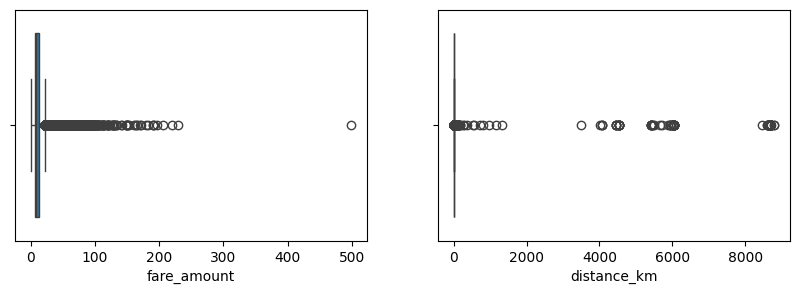

fare_amount outliers: 16619
distance_km outliers: 8006
Shape after cleaning: (169019, 8)


In [5]:
fig,ax = plt.subplots(1,2,figsize=(10,3))
sns.boxplot(x=df["fare_amount"],ax=ax[0]); sns.boxplot(x=df["distance_km"],ax=ax[1]); plt.show()
for c in ["fare_amount","distance_km"]:
    q1,q3 = df[c].quantile([.25,.75]); iqr = q3-q1; lo,hi = q1-1.5*iqr, q3+1.5*iqr
    print(c,"outliers:",((df[c]<lo)|(df[c]>hi)).sum())
    df = df[(df[c]>=lo)&(df[c]<=hi)]                    # remove them
print("Shape after cleaning:", df.shape)

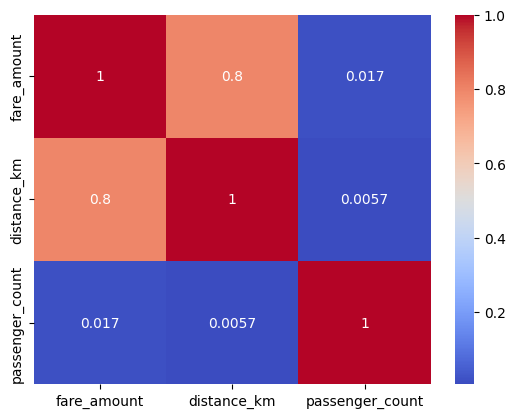

In [6]:
corr = df[["fare_amount","distance_km","passenger_count"]].corr()
sns.heatmap(corr,annot=True,cmap="coolwarm"); plt.show()

In [7]:
X, y = df[["distance_km","passenger_count"]], df["fare_amount"]
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
models = {"Linear Regression":LinearRegression(),
          "Random Forest":RandomForestRegressor(n_estimators=50,random_state=42,n_jobs=-1)}

In [8]:
rows = []
for name,m in models.items():
    p = m.fit(X_train,y_train).predict(X_test)
    rows.append([name, r2_score(y_test,p), np.sqrt(mean_squared_error(y_test,p)), mean_absolute_error(y_test,p)])
print(pd.DataFrame(rows,columns=["Model","R2","RMSE","MAE"]))

               Model        R2      RMSE       MAE
0  Linear Regression  0.637790  2.238366  1.612369
1      Random Forest  0.500554  2.628423  1.900070
